# 🚀 TrendPilot - Local Agentic AI Content Planner (+ StudyBuddy mode)
**AIRI Team PITB - AI Internship Task 2 · Hamza Nadeem**

An end-to-end **agent** (not a chatbot) running on a **local LLM (Gemma 3:4B via Ollama)**. Give it a topic, platform and tone - it
understands the request, **plans which tools to use**, calls them (idea generator, caption writer, hashtag generator, reel script,
title/thumbnail, reviewer, file saver, memory), **reviews and rewrites its own weak parts**, saves the result and remembers it.

### How to run (once)
1. Upload **`agentic_ai_task_2.zip`** to the main folder of your Google Drive (**My Drive**). Do not unzip it.
2. **Runtime → Change runtime type → T4 GPU → Save**.
3. **Runtime → Run all**. Allow Google Drive access when asked.
4. Wait ~35-45 minutes (model download + 20 test runs). Everything is saved back to `My Drive/agentic_ai_task_2/`.

At the end you get: screenshots, 10 test results (v1 vs v2), the error-analysis table, `report/final_report.pdf`,
the LinkedIn report and a ready-to-upload `agentic_ai_task_2_final.zip`.

## Step 1 - Check the GPU

In [ ]:
import subprocess
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader", shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "No GPU found - Runtime > Change runtime type > T4 GPU (CPU works but is ~10x slower)")

GPU: Tesla T4, 15360 MiB


## Step 2 - Get the project from Google Drive

In [ ]:
import os, sys, shutil, zipfile, json, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
WORK = Path(os.environ.get("TP_PROJECT_DIR", "/content/agentic_ai_task_2"))     # fast local copy we work in
DRIVE_ROOT = Path("/content/drive/MyDrive")
DRIVE_DIR = DRIVE_ROOT / "agentic_ai_task_2"                                      # results are copied back here

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def unpack(zip_path, dest):
    tmp = Path("/content/_unzip"); shutil.rmtree(tmp, ignore_errors=True)
    zipfile.ZipFile(zip_path).extractall(tmp)
    inner = next((p.parent for p in tmp.rglob("demo.py") if "__MACOSX" not in str(p)), tmp)
    shutil.copytree(inner, dest)

if not (WORK / "app" / "agent.py").exists():
    if (DRIVE_DIR / "app" / "agent.py").exists():
        shutil.copytree(DRIVE_DIR, WORK, dirs_exist_ok=True)                          # continue from a previous session
    elif (DRIVE_ROOT / "agentic_ai_task_2.zip").exists():
        unpack(DRIVE_ROOT / "agentic_ai_task_2.zip", WORK)
    elif IN_COLAB:
        from google.colab import files
        print("Zip not found in My Drive - please upload agentic_ai_task_2.zip now")
        up = files.upload(); unpack(next(iter(up)), WORK)
    else:
        raise FileNotFoundError("Project not found")

os.chdir(WORK); sys.path.insert(0, str(WORK))
for d in ["screenshots", "report", "tests", "outputs/logs"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
print("Project folder:", WORK)
print(sorted(p.name for p in WORK.iterdir()))

Mounted at /content/drive
Project folder: /content/agentic_ai_task_2
['.gitignore', 'README.md', 'app', 'demo.py', 'notebooks', 'outputs', 'report', 'requirements.txt', 'screenshots', 'scripts', 'tests']


## Step 3 - Install Python packages

In [ ]:
!pip install -q -r requirements.txt
print("Packages installed")

Packages installed


## Step 4 - Install Ollama, start the server and download Gemma 3:4B
Ollama runs the model **locally on the Colab GPU** - no paid API. The model download is ~3.3 GB (2-4 minutes).

In [ ]:
import requests, subprocess, time, os
MODEL = os.environ.get("TRENDPILOT_MODEL", "gemma3:4b")
OLLAMA_URL = os.environ.get("OLLAMA_HOST_URL", "http://localhost:11434")

def ollama_up():
    try:
        return requests.get(f"{OLLAMA_URL}/api/version", timeout=3).ok
    except Exception:
        return False

if not ollama_up():
    if shutil.which("ollama") is None:
        !sudo apt-get -qq install -y zstd pciutils lshw > /dev/null 2>&1
        !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
    env = dict(os.environ, OLLAMA_KEEP_ALIVE="30m")
    subprocess.Popen(["ollama", "serve"], stdout=open("/content/ollama.log", "w"), stderr=subprocess.STDOUT, env=env)
    for _ in range(60):
        if ollama_up(): break
        time.sleep(1)
print("Ollama server running:", ollama_up())

t0 = time.time()
!ollama pull {MODEL} 2>&1 | tail -n 2
print(f"Model ready in {time.time()-t0:.0f}s")

Ollama server running: True
writing manifest 
success 
Model ready in 41s


## Step 5 - Test the model (brief section 10, step 3) → `screenshots/ollama_running.png`
Runs `ollama --version`, `ollama list` and the test prompt from the brief, then saves the real terminal output as a screenshot.

In [ ]:
import re
from scripts.screens import terminal_png

def sh(cmd, timeout=600):
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=timeout)
    text = (out.stdout + out.stderr)
    text = re.sub(r"\x1b\[[0-9;?]*[a-zA-Z]", "", text)                   # remove terminal colour/spinner codes
    text = re.sub(r"[⠀-⣿]", "", text)                                    # remove spinner characters
    return "\n".join(l.rstrip() for l in text.splitlines()).strip()

TEST_PROMPT = "Give me 5 viral LinkedIn post ideas about AI internships."
log = []
for cmd in ["ollama --version", "ollama list", f'ollama run {MODEL} "{TEST_PROMPT}"']:
    t0 = time.time()
    res = sh(cmd)
    log.append(f"$ {cmd}\n{res}" + (f"\n[{time.time()-t0:.1f}s]" if "run" in cmd else ""))
    print(log[-1], "\n")
gpu_line = sh("nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv,noheader")
log.append(f"$ nvidia-smi --query-gpu=name,memory.used,memory.total\n{gpu_line}")
terminal_png("\n\n".join(log), "screenshots/ollama_running.png", f"Google Colab - Ollama running {MODEL} locally", max_lines=70)
OLLAMA_VERSION = sh("ollama --version").split()[-1] if sh("ollama --version") else "?"
print("Saved screenshots/ollama_running.png")

$ ollama --version
ollama version is 0.40.14 

$ ollama list
NAME         ID              SIZE      MODIFIED
gemma3:4b    68ceab7e468a    3.4 GB    Less than a second ago 

$ ollama run gemma3:4b "Give me 5 viral LinkedIn post ideas about AI internships."
Okay, here are 5 viral LinkedIn post ideas about AI internships, designed to grab attention and encourage engagement, with suggested visuals and a focus on what makes them shareable:

**1. Post Idea: The "AI Internship Myth" - Honest & Relatable**

* **Visual:** A slightly humorous graphic - maybe a bewildered-looking person surrounded by code, or a meme-style image about feeling overwhelmed.
* **Text:** “Let’s be real, the AI internship landscape can feel *wild*.  I'm seeing a ton of hype about ‘guaranteed jobs’ and ‘instant mastery.’  The truth is, most internships are competitive, require serious dedication, and a willingness to learn *a lot*.  What’s the #1 thing you wish you’d known going into your AI internship?  Let’s destigmat

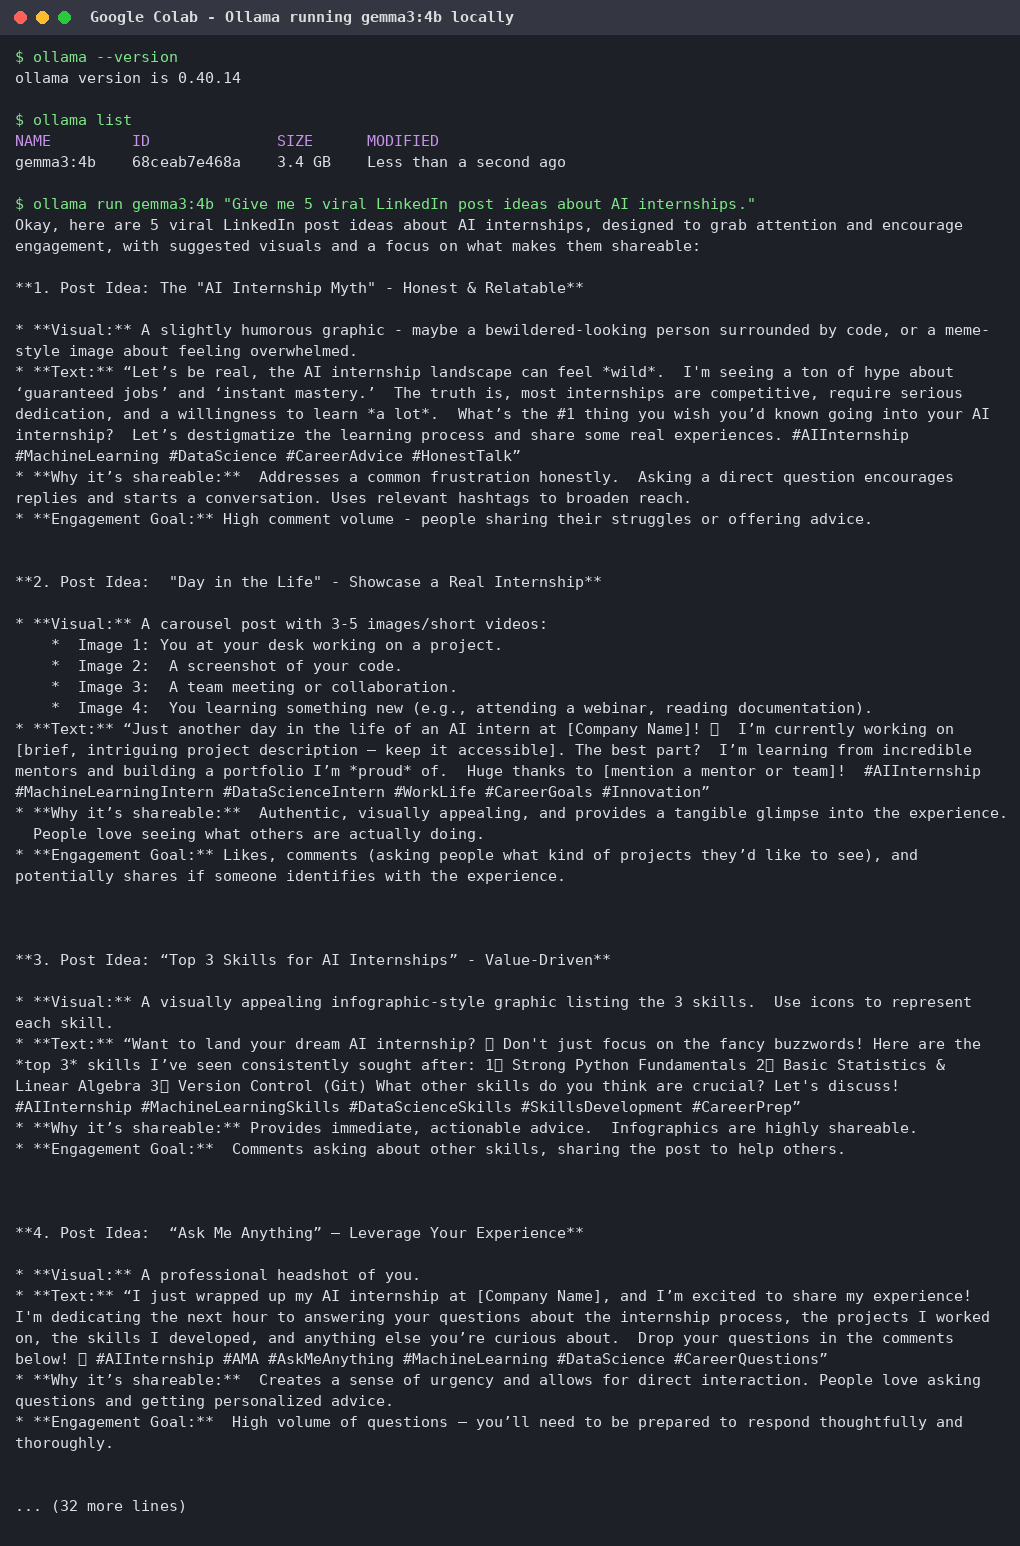

In [ ]:
from IPython.display import Image, display
display(Image("screenshots/ollama_running.png", width=900))

## Step 6 - Basic Python connection to Ollama (brief section 11)

In [ ]:
import requests

def ask_ollama(prompt, model=MODEL):
    url = f"{OLLAMA_URL}/api/generate"
    payload = {"model": model, "prompt": prompt, "stream": False}
    response = requests.post(url, json=payload, timeout=300)
    response.raise_for_status()
    return response.json()["response"]

result = ask_ollama("Give me 5 viral AI project ideas for LinkedIn.")
print(result)

Okay, here are 5 viral AI project ideas tailored for LinkedIn, focusing on engagement, demonstrating skill, and leveraging current trends. I've included estimated difficulty and potential audience appeal:

**1. "AI Prompt Generator for [Specific Industry]" (Difficulty: Medium - High)**

* **Concept:** Build a simple web app (using Streamlit, Gradio, or a similar low-code platform) that takes a user's industry (e.g., Marketing, Software Development, Healthcare, Education) and generates a list of effective prompts for ChatGPT, Claude, or Gemini.  The app could even offer variations for different prompt types (e.g., brainstorming, outline creation, code generation).
* **Viral Factor:**  Everyone is using AI and struggling to get the *right* prompts.  People love tools that make their lives easier and demonstrate they’re getting results from AI.  Specificity is key – "AI Prompt Generator for Lawyers" will resonate more than "AI Prompt Generator."
* **LinkedIn Appeal:** Showcases prompt eng

## Step 7 - The agent and its tools
`app/tools.py` has a **tool registry**. The planner (LLM) chooses tools from this list for every request - a reel request gets
the script tool, a LinkedIn post gets caption + hashtags, a StudyBuddy request gets the study tools.

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)
from app.config import Settings
from app.agent import TrendPilotAgent
from app.tools import REGISTRY

settings = Settings()
agent = TrendPilotAgent(settings)
print("Model in use:", agent.llm.ensure_model(), "| LangGraph:", agent.graph is not None)
pd.DataFrame([{"Tool": t.display_name, "Mode": t.mode, "Uses LLM": t.uses_llm, "What it does": t.description}
              for t in REGISTRY.values()])

Model in use: gemma3:4b | LangGraph: True


,Tool,Mode,Uses LLM,What it does
0,Simple Memory Tool,shared,False,"Recall previous topics, platforms, styles and hooks from long-term memory (SQLite) so the new content is fresh."
1,Web Trend Research (DuckDuckGo),content,False,"Search the web (DuckDuckGo) for fresh, real context about the topic so the content is current and factual."
2,Trend Idea Generator,content,True,"Generate 5 viral content angles for the topic and platform, score them and select the best one."
3,Caption Writer,content,True,"Write the hook, the full platform-ready post caption and a call to action in the requested tone."
4,Hashtag Generator,content,True,"Generate relevant hashtags for the platform (right count, broad + niche, no spam tags)."
5,Reel Script Generator,content,True,"Create a 15-60 second short-video script: opening hook, explanation, visual suggestions and closing line."
6,Title and Thumbnail Text Generator,content,True,Generate catchy video/post titles and short thumbnail text.
7,Post Image Prompt Generator,content,True,Write a prompt for an AI image generator to create the post's cover image (optional extra).
8,Content Reviewer,content,True,"Review the content (hook strength, clarity, length, tone, hashtag relevance, platform readiness) and decide what to ..."
9,File Saver Tool,shared,False,"Save the final result as Markdown + JSON in outputs/ (posts, scripts, full results). Mandatory last step."


## Step 8 - Main example from the brief (CLI demo) → `screenshots/demo_output.png`
Runs the real CLI (`python demo.py ...`). Watch the `[Tool Called]` lines: the agent plans, calls tools, reviews itself and saves.

In [ ]:
EXAMPLE = dict(topic="I want to create a viral LinkedIn post about my YOLOv8 helmet detection project",
               platform="LinkedIn", tone="Professional but exciting", output="Post + Reel Script")
cmd = [sys.executable, "-u", "demo.py", "--topic", EXAMPLE["topic"], "--platform", EXAMPLE["platform"],
       "--tone", EXAMPLE["tone"], "--output", EXAMPLE["output"]]
before = set((WORK / "outputs/saved_results").glob("*.json"))
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
cli_lines = []
for line in proc.stdout:
    print(line, end=""); cli_lines.append(line.rstrip())
proc.wait()
cli_text = "$ python demo.py --topic \"...YOLOv8 helmet detection project\" --platform LinkedIn --tone \"Professional but exciting\" --output \"Post + Reel Script\"\n" + "\n".join(cli_lines)
terminal_png(cli_text, "screenshots/demo_output.png", "TrendPilot CLI demo - python demo.py", max_lines=95)
example_json = max(set((WORK / "outputs/saved_results").glob("*.json")) - before, key=lambda p: p.stat().st_mtime)
res = json.loads(example_json.read_text())
SHOW = {"model": res["model"], "ollama_version": OLLAMA_VERSION, "gpu": gpu or "CPU", "example_json": str(example_json)}
json.dump(SHOW, open("outputs/logs/showcase.json", "w"), indent=2)
print("\nSaved screenshots/demo_output.png and", example_json.name)


  _____                    _ ____  _ _       _
 |_   _| __ ___ _ __   __| |  _ \(_) | ___ | |_
   | || '__/ _ \ '_ \ / _` | |_) | | |/ _ \| __|
   | || | |  __/ | | | (_| |  __/| | | (_) | |_
   |_||_|  \___|_| |_|\__,_|_|   |_|_|\___/ \__|   Local Agentic AI (Ollama)

Ollama OK - model: gemma3:4b

=== TrendPilot | I want to create a viral LinkedIn post about my YOLOv8 helmet detection project ===
[Tool Called]: Simple Memory Tool -> {'recalled_runs': 0, 'preferences': {}}  (0.0s)
[Tool Called]: Web Trend Research (DuckDuckGo) -> {'results': 5, 'query': 'I want to create a viral LinkedIn post about my YOLOv8 helmet detection project LinkedIn tips'}  (1.3s)
[Agent Step]: Understand goal -> {'audience': 'Computer vision engineers, robotics students, AI researchers, and anyone interes'}  (4.5s)
[Plan]: Planner agent -> trend_idea_generator -> caption_writer -> reel_script_generator -> hashtag_generator -> content_reviewer -> file_saver  (4.3s)
[Tool Called]: Trend Idea Generator -> {'ang

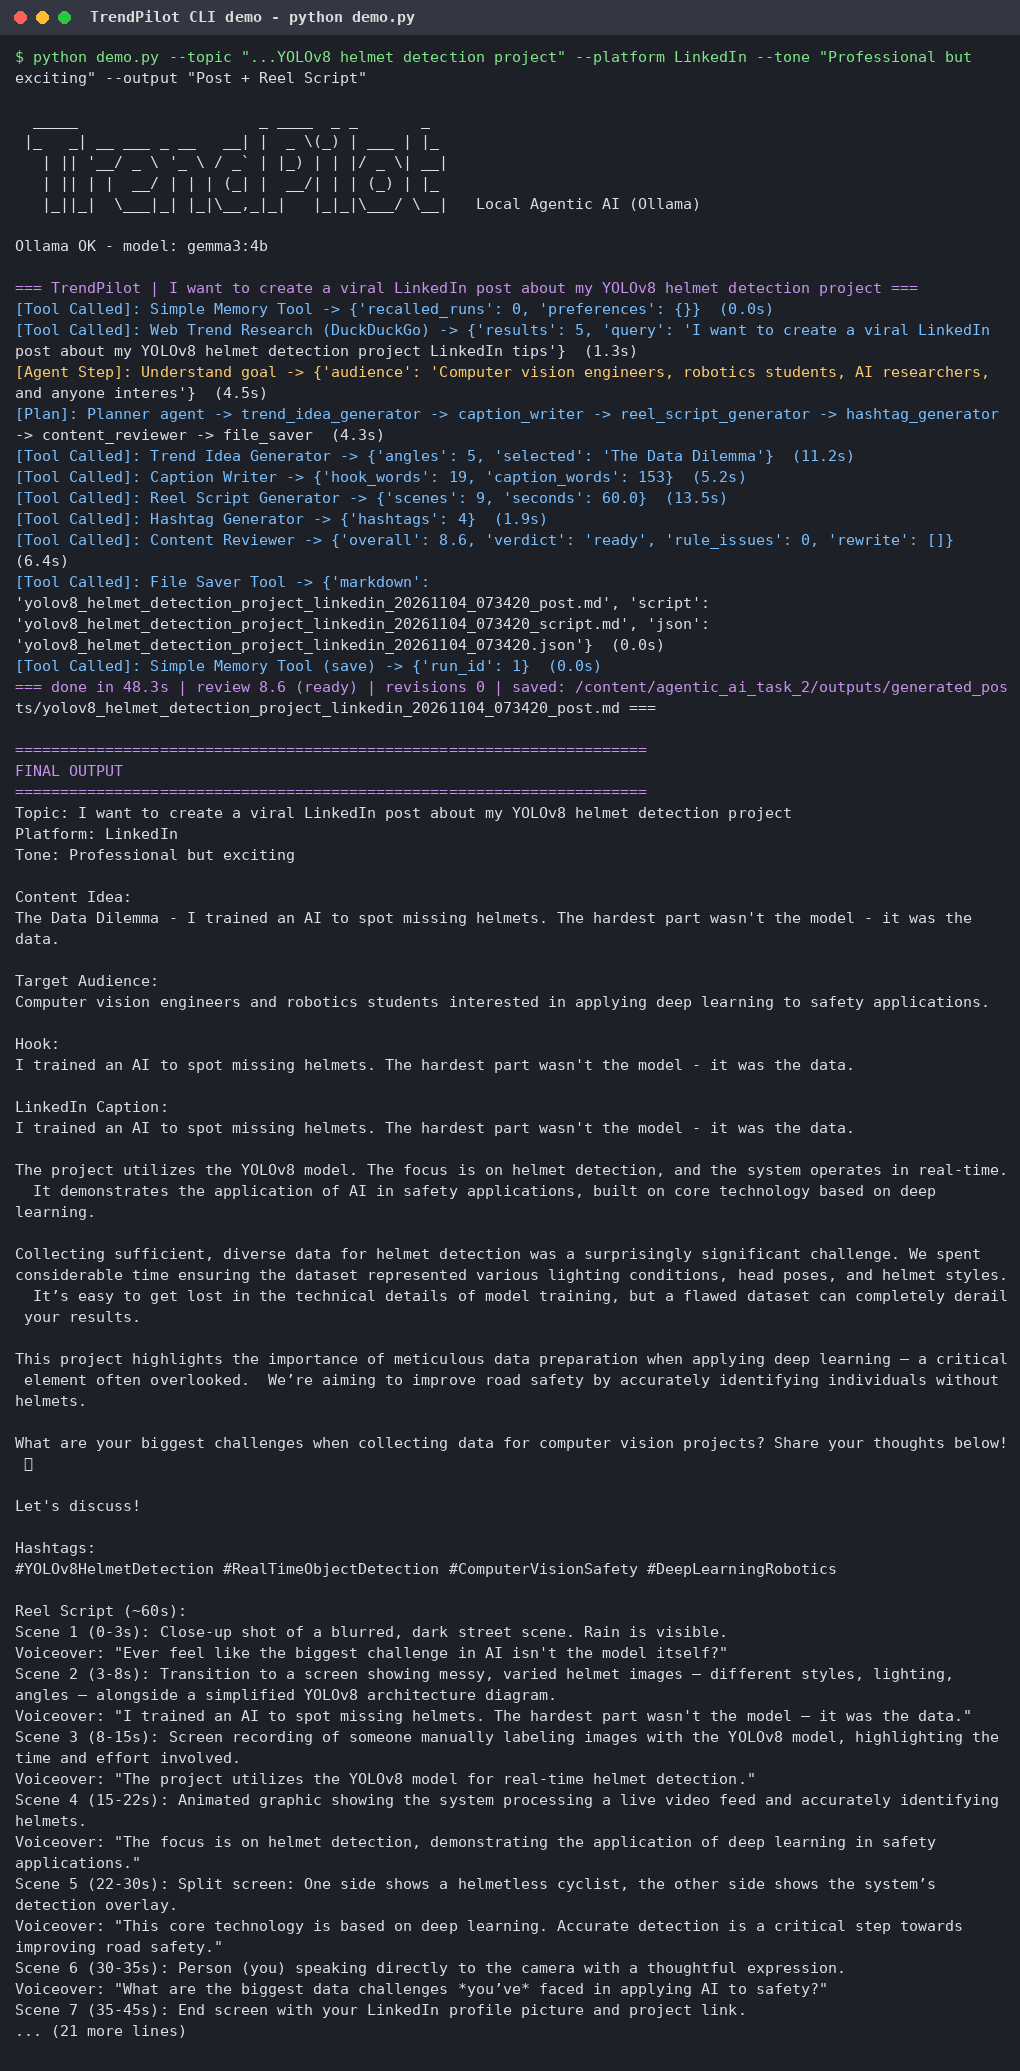

# I want to create a viral LinkedIn post about my YOLOv8 helmet detection project

**Platform:** LinkedIn  |  **Tone:** Professional but exciting  |  **Output:** Post + Reel Script  
**Generated:** 2026-11-04 07:34:20  |  **Model:** gemma3:4b  |  **Prompt version:** v2

## Content Idea
**The Data Dilemma** - I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data.

*Why it works:* Relatable – everyone struggles with data. Highlights a key issue in practical AI development.

## Target Audience
Computer vision engineers and robotics students interested in applying deep learning to safety applications.

## Viral Hook
> I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data.

## Post Caption
I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data.

The project utilizes the YOLOv8 model. The focus is on helmet detection, and the system operates in real-time.  It demonstrates the application of AI in safety applications, built on core technology based on deep learning. 

Collecting sufficient, diverse data for helmet detection was a surprisingly significant challenge. We spent considerable time ensuring the dataset represented various lighting conditions, head poses, and helmet styles.  It’s easy to get lost in the technical details of model training, but a flawed dataset can completely derail your results. 

This project highlights the importance of meticulous data preparation when applying deep learning – a critical element often overlooked.  We’re aiming to improve road safety by accurately identifying individuals without helmets.

What are your biggest challenges when collecting data for computer vision projects? Share your thoughts below! 🧐

Let's discuss!

## Hashtags
#YOLOv8HelmetDetection #RealTimeObjectDetection #ComputerVisionSafety #DeepLearningRobotics

## Reel / Short Video Script (~60s)

| Time | Visual | Voiceover | On-screen text |
|---|---|---|---|
| 0-3s | Close-up shot of a blurred, dark street scene. Rain is visible. | Ever feel like the biggest challenge in AI isn't the model itself? | The Data Dilemma |
| 3-8s | Transition to a screen showing messy, varied helmet images – different styles, lighting, angles – alongside a simplified YOLOv8 architecture diagram. | I trained an AI to spot missing helmets. The hardest part wasn't the model – it was the data. | Helmet Detection Project |
| 8-15s | Screen recording of someone manually labeling images with the YOLOv8 model, highlighting the time and effort involved. | The project utilizes the YOLOv8 model for real-time helmet detection. | Real-time AI Safety |
| 15-22s | Animated graphic showing the system processing a live video feed and accurately identifying helmets. | The focus is on helmet detection, demonstrating the application of deep learning in safety applications. | Deep Learning in Action |
| 22-30s | Split screen: One side shows a helmetless cyclist, the other side shows the system’s detection overlay. | This core technology is based on deep learning. Accurate detection is a critical step towards improving road safety. | Improving Road Safety |
| 30-35s | Person (you) speaking directly to the camera with a thoughtful expression. | What are the biggest data challenges *you’ve* faced in applying AI to safety? | Data Challenges? Share! |
| 35-45s | End screen with your LinkedIn profile picture and project link. | Explore the full project details here: [link] | Learn More & Follow |
| 45-50s | Quick montage of the images and visualizations from the video. |  | Helmet Detection |
| 50-60s | Final shot – a cyclist wearing a helmet riding confidently on a sunny road. | Let’s build safer roads, together. | Road Safety Now! |

**Closing line:** What’s your biggest AI safety challenge?

## Content Review & Improvement Suggestions
**Score:** 8.6 / 10  |  **Verdict:** ready  |  **Revisions made:** 0

hook strength: 9, clarity: 8, length fit: 9, tone fit: 8, hashtag relevance: 7, platform readiness: 9

- Streamline the reel script to highlight the core challenge – data – more powerfully. Reduce the screen recordings to focus on the key visual impact.
- Consider a more evocative opening for the reel. Instead of stating the problem, show a brief, impactful visual of a near-miss situation (without explicitly showing a helmetless rider) to immediately grab attention.

Remaining issues:
- The reel script is overly detailed and could benefit from a tighter focus. The pacing feels slightly rushed.
- The voiceover script is a bit too explanatory; it leans into technical jargon that might not immediately resonate with a LinkedIn audience.

## Web Sources Checked
- https://www.linkedin.com/pulse/how-create-viral-linkedin-posts-drive-engagement-75i4f
- https://contentin.io/linkedin-post-templates/go-viral/
- https://www.linkedin.com/pulse/how-write-viral-linkedin-post-get-high-impressions-delta-garg-b4dgf?tl=en
- https://www.viralbrain.ai/guides/how-to-go-viral-on-linkedin
- https://posteverywhere.ai/blog/how-to-go-viral-on-linkedin

## Agent Trace
Tools called: Simple Memory Tool -> Web Trend Research (DuckDuckGo) -> Trend Idea Generator -> Caption Writer -> Reel Script Generator -> Hashtag Generator -> Content Reviewer


In [ ]:
from IPython.display import Markdown
display(Image("screenshots/demo_output.png", width=950))
display(Markdown(Path(res["final_output"]["saved_file"]).read_text()))

## Step 9 - User feedback loop
The user asks for a change; an LLM router decides **which tools to re-run** (only those), the reviewer checks again and a new
`_revised` file is saved.

In [ ]:
FEEDBACK = "Make the hook shorter and more surprising, and add one line about what I learned from the project."
revised = agent.revise(res, FEEDBACK)
print("\nBEFORE hook:", res["artifacts"].get("hook"))
print("AFTER  hook:", revised["artifacts"].get("hook"))
print("Re-ran tools:", revised["revised_tools"], "| score", res["review"].get("overall"), "->", revised["review"].get("overall"))
print("Saved:", revised["saved_files"].get("markdown"))
json.dump(revised, open("outputs/logs/revised_example.json", "w"), indent=2, default=str)
SHOW.update(revised_json="outputs/logs/revised_example.json", feedback=FEEDBACK)
json.dump(SHOW, open("outputs/logs/showcase.json", "w"), indent=2)

[Revision]: User feedback -> "Make the hook shorter and more surprising, and add one line about what I learned from the project." -> ['caption_writer', 'reel_script_generator']
[Tool Called]: Caption Writer -> {'hook_words': 19, 'caption_words': 139}  (5.3s)
[Tool Called]: Reel Script Generator -> {'scenes': 7, 'seconds': 60.0}  (10.3s)
[Tool Called]: Content Reviewer -> {'overall': 8.6, 'verdict': 'ready', 'rule_issues': 0, 'rewrite': []}  (6.6s)
[Tool Called]: File Saver Tool -> {'markdown': 'yolov8_helmet_detection_project_linkedin_20261104_073445_revised_post.md', 'script': 'yolov8_helmet_detection_project_linkedin_20261104_073445_revised_script.md', 'json': 'yolov8_helmet_detection_project_linkedin_20261104_073445_revised.json'}  (0.0s)
[Tool Called]: Simple Memory Tool (save) -> {'run_id': 2}  (0.0s)

BEFORE hook: I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data.
AFTER  hook: I trained an AI to spot missing helmets. The hardest part was

## Step 10 - Memory
Long-term memory is SQLite (`outputs/memory.db`): past runs, learned preferences and study progress. Before every run the
**Simple Memory Tool** recalls similar topics so the agent does not repeat the same hook.

In [ ]:
print("Learned preferences:", agent.memory.prefs())
print("\nWhat the agent will remember next time it writes about YOLOv8:\n")
print(agent.memory.memory_notes("YOLOv8 helmet detection project", "LinkedIn"))
pd.DataFrame(agent.memory.history(10))

Learned preferences: {'favourite_platform': 'LinkedIn', 'favourite_tone': 'Professional but exciting'}

What the agent will remember next time it writes about YOLOv8:

Previous topic: I want to create a viral LinkedIn post about my YOLOv8 helmet detection project (LinkedIn, Professional but exciting); hook used: "I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the da" | Previous topic: I want to create a viral LinkedIn post about my YOLOv8 helmet detection project (LinkedIn, Professional but exciting); hook used: "I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the da" -> use a fresh angle and a different hook.


,id,created_at,topic,platform,tone,output_type,review_score,verdict,saved_md
0,2,2026-11-04 07:34:45,I want to create a viral LinkedIn post about my YOLOv8 helmet detection project,LinkedIn,Professional but exciting,Post + Reel Script,8.6,ready,/content/agentic_ai_task_2/outputs/generated_posts/yolov8_helmet_detection_project_linkedin_20261104_073445_revised_...
1,1,2026-11-04 07:34:20,I want to create a viral LinkedIn post about my YOLOv8 helmet detection project,LinkedIn,Professional but exciting,Post + Reel Script,8.6,ready,/content/agentic_ai_task_2/outputs/generated_posts/yolov8_helmet_detection_project_linkedin_20261104_073420_post.md


## Step 11 - StudyBuddy mode (same agent engine, different tools)

In [ ]:
study = agent.run_study("Object detection with YOLOv8", days=5, level="Beginner", hours_per_day=2)
pid = study["artifacts"].get("plan_id")
quiz = study["artifacts"].get("quiz", {}).get("questions", [])
print("\nQuiz example:", quiz[0]["question"] if quiz else "-")
print("Progress after finishing day 1 with 80% quiz score:", agent.memory.update_progress(pid, 1, True, 80) if pid else "-")
json.dump(study, open("outputs/logs/study_example.json", "w"), indent=2, default=str)
SHOW.update(study_json="outputs/logs/study_example.json")
json.dump(SHOW, open("outputs/logs/showcase.json", "w"), indent=2)
display(Markdown(Path(study["saved_files"]["markdown"]).read_text()[:3500]))


=== StudyBuddy | Object detection with YOLOv8 ===
[Tool Called]: Simple Memory Tool -> {'recalled': 'no related study plans'}  (0.0s)
[Plan]: Study plan -> study_planner -> notes_generator -> quiz_generator -> study_reviewer -> progress_saver -> file_saver
[Tool Called]: Study Planner -> {'days': 5}  (30.2s)
[Tool Called]: Notes Generator -> {'concepts': 10}  (15.6s)
[Tool Called]: Quiz Generator -> {'questions': 8}  (22.6s)
[Tool Called]: Study Pack Reviewer -> {'overall': 8.2, 'verdict': 'ready'}  (4.7s)
[Tool Called]: Progress Saver -> {'plan_id': 1, 'days_tracked': 5}  (0.0s)
[Tool Called]: File Saver Tool -> {'markdown': 'study_object_detection_with_yolov8_5days_20261104_073558.md', 'json': 'study_object_detection_with_yolov8_5days_20261104_073558.json'}  (0.0s)
=== done in 73.1s | review 8.2 (ready) | revisions 0 | saved: /content/agentic_ai_task_2/outputs/study_plans/study_object_detection_with_yolov8_5days_20261104_073558.md ===

Quiz example: In YOLOv8, what is the primary go

# YOLOv8 Object Detection: Your 5-Day Launchpad

**Topic:** Object detection with YOLOv8  |  **Days:** 5  |  **Level:** Beginner  |  **Time/day:** 2.0 h  
**Plan ID (progress tracking):** 1  |  **Generated:** 2026-11-04 07:35:58

## Daily Study Plan
### Day 1: Introduction to Object Detection and YOLO (120 min)
- Goal: Understand the fundamentals of object detection.
- Goal: Learn about the YOLO architecture and its evolution.
- Goal: Become familiar with the core components of YOLOv8.
- [ ] Read: PyTorch documentation on Automatic Differentiation - [https://pytorch.org/docs/stable/autograd.html](https://pytorch.org/docs/stable/autograd.html)
- [ ] Watch: YouTube - 'YOLOv8 Explained' - (approx. 30 mins) - [https://www.youtube.com/watch?v=l4qgH-4wVj0](https://www.youtube.com/watch?v=l4qgH-4wVj0)
- [ ] Read: YOLOv8 Documentation - Overview and Architecture - [https://docs.ultralytics.com/yolov8/getting_started/introduction](https://docs.ultralytics.com/yolov8/getting_started/introduction)
- [ ] Code: Explore a basic YOLOv8 implementation (e.g., find a simple demo on GitHub) - (approx. 30 mins)
- Resources: PyTorch Documentation (docs); YOLOv8 Explained Video (video); YOLOv8 Documentation - Architecture (docs)

### Day 2: YOLOv8 Training and Configuration (120 min)
- Goal: Understand the training process of YOLOv8.
- Goal: Learn how to configure training parameters.
- Goal: Become familiar with the datasets used for training.
- [ ] Read: YOLOv8 Documentation - Training - [https://docs.ultralytics.com/yolov8/training/](https://docs.ultralytics.com/yolov8/training/)
- [ ] Watch: YouTube - 'YOLOv8 Training Tutorial' - (approx. 45 mins) - [https://www.youtube.com/watch?v=9nQ-wV33J5I](https://www.youtube.com/watch?v=9nQ-wV33J5I)
- [ ] Code: Experiment with a pre-trained YOLOv8 model's configuration file - (approx. 30 mins)
- [ ] Read: COCO Dataset Documentation - [https://cocodataset.org/#download](https://cocodataset.org/#download)
- Resources: YOLOv8 Training Documentation (docs); YOLOv8 Training Tutorial Video (video); COCO Dataset Documentation (docs)

### Day 3: Inference with YOLOv8 (120 min)
- Goal: Learn how to perform inference with a trained YOLOv8 model.
- Goal: Understand the different inference methods.
- Goal: Practice deploying a model for object detection.
- [ ] Read: YOLOv8 Documentation - Inference - [https://docs.ultralytics.com/yolov8/inference/](https://docs.ultralytics.com/yolov8/inference/)
- [ ] Code: Run a pre-trained YOLOv8 model on a sample image - (approx. 60 mins)
- [ ] Code: Experiment with different inference parameters (e.g., confidence threshold) - (approx. 30 mins)
- [ ] Watch: YouTube - 'YOLOv8 Inference Tutorial' - (approx. 30 mins) - [https://www.youtube.com/watch?v=4yO0K-eB_xU](https://www.youtube.com/watch?v=4yO0K-eB_xU)
- Resources: YOLOv8 Inference Documentation (docs); YOLOv8 Inference Tutorial Video (video)

### Day 4: Custom Dataset and Training (120 min)
- Goal: Prepare a custom dataset for YOLOv8.
- Goal: Train a YOLOv8 model from scratch using your dataset.
- Goal: Evaluate the performance of the trained model.
- [ ] Read: YOLOv8 Documentation - Custom Dataset - [https://docs.ultralytics.com/yolov8/data/custom_dataset](https://docs.ultralytics.com/yolov8/data/custom_dataset)
- [ ] Code: Annotate a small custom dataset using a tool like LabelImg - (approx. 60 mins)
- [ ] Code: Train a YOLOv8 model on your custom dataset - (approx. 60 mins)
- [ ] Code: Evaluate the model's performance using metrics l

## Step 12 - Testing: the 10 test cases from the brief (v1 baseline) ⏱ ~8-10 min
**v1** = simple prompts, fixed tool pipeline, no review loop. Its outputs go to `outputs/baseline_v1/` so they don't mix with the
final outputs.

In [ ]:
from app.evaluation import TEST_CASES, run_suite, compare, error_analysis, write_test_cases_md

s1 = Settings(); s1.prompt_version = "v1"; s1.verbose = False
s1.outputs_dir = WORK / "outputs" / "baseline_v1"; s1.memory_db = s1.outputs_dir / "memory_v1.db"
t0 = time.time()
v1 = run_suite(TrendPilotAgent(s1), label="v1", out_dir=WORK / "outputs" / "logs")
print(f"v1 done in {(time.time()-t0)/60:.1f} min")

  [v1] test  1: score 7.65 | useful Partly | issues ['too_many_hashtags', 'tool_failed']
  [v1] test  2: score 7.1 | useful Partly | issues ['hashtags_in_caption', 'too_many_hashtags']
  [v1] test  3: score 7.35 | useful Partly | issues ['too_many_hashtags', 'tool_failed']
  [v1] test  4: score 3.95 | useful No | issues ['over_char_limit', 'possible_invented_metric', 'too_many_hashtags']
  [v1] test  5: score 5.8 | useful No | issues ['too_short', 'too_many_hashtags']
  [v1] test  6: score 8.6 | useful Yes | issues []
  [v1] test  7: score 6.95 | useful Partly | issues ['hashtags_in_caption', 'possible_invented_metric', 'too_many_hashtags']
  [v1] test  8: score 8.3 | useful Yes | issues []
  [v1] test  9: score 8.05 | useful Partly | issues ['too_many_hashtags']
  [v1] test 10: score 9.2 | useful Yes | issues []
v1 done in 12.8 min


## Step 13 - Testing: the same 10 cases with the final agent (v2) ⏱ ~20-25 min

In [ ]:
s2 = Settings(); s2.verbose = False
t0 = time.time()
v2 = run_suite(TrendPilotAgent(s2), label="v2", out_dir=WORK / "outputs" / "logs")
print(f"v2 done in {(time.time()-t0)/60:.1f} min")
pd.DataFrame(compare(v1, v2))

  [v2] test  1: score 8.55 | useful Yes | issues ['possible_invented_metric']
  [v2] test  2: score 8.8 | useful Yes | issues []
  [v2] test  3: score 8.3 | useful Yes | issues []
  [v2] test  4: score 6.5 | useful Partly | issues ['low_review_score']
  [v2] test  5: score 8.2 | useful Yes | issues []
  [v2] test  6: score 8.3 | useful Yes | issues []
  [v2] test  7: score 8.8 | useful Yes | issues []
  [v2] test  8: score 8.2 | useful Yes | issues []
  [v2] test  9: score 8.2 | useful Yes | issues []
  [v2] test 10: score 8.3 | useful Yes | issues []
v2 done in 6.1 min


,Test,Topic,Platform,v1 score,v1 issues,v1 useful,v2 score,v2 issues,v2 useful,v2 self-revisions
0,1,YOLOv8 helmet detection,LinkedIn,7.65,2,Partly,8.55,1,Yes,0
1,2,AI internship experience,LinkedIn,7.10,2,Partly,8.80,0,Yes,0
2,3,Python learning journey,Instagram Reels,7.35,2,Partly,8.30,0,Yes,0
3,4,Machine learning project,X / Twitter,3.95,3,No,6.50,1,Partly,0
4,5,Data annotation struggles,LinkedIn,5.80,2,No,8.20,0,Yes,0
5,6,Model failed in production,Instagram Reels,8.60,0,Yes,8.30,0,Yes,0
6,7,Final year project,LinkedIn,6.95,3,Partly,8.80,0,Yes,0
7,8,Computer vision project,YouTube Shorts,8.30,0,Yes,8.20,0,Yes,0
8,9,Debugging FastAPI,X / Twitter,8.05,1,Partly,8.20,0,Yes,0
9,10,Open-source contribution,LinkedIn,9.20,0,Yes,8.30,0,Yes,0


## Step 14 - Error analysis + `tests/test_cases.md`
Weak/failed answers are detected automatically (platform rules + reviewer score). Read some outputs yourself and, if you want,
add your own observations to `MANUAL_REVIEW_NOTES` (test number → note); they go into the report.

In [ ]:
MANUAL_REVIEW_NOTES = {
    # 5: "Humour felt forced - small 4B models are weaker at jokes than at technical posts.",
}
errors = error_analysis(v1, v2, manual_notes=MANUAL_REVIEW_NOTES)
write_test_cases_md("tests/test_cases.md", v1, v2, errors, res["model"])
SHOW["manual_notes"] = MANUAL_REVIEW_NOTES
json.dump(SHOW, open("outputs/logs/showcase.json", "w"), indent=2)
pd.DataFrame(errors).drop(columns=["code"])

,Test Case,Problem Found,Possible Reason,Fix Applied,Result After Fix (v2)
0,"#4 Machine learning project (X / Twitter, Short and catchy)",350 characters incl. hashtags > X / Twitter limit 280.,X/Twitter's 280-character limit (incl. hashtags) was never mentioned,Added the 280-character rule and an automatic character-count check,fixed - score 3.95 -> 6.5
1,"#5 Data annotation struggles (LinkedIn, Humorous)",Caption has only 50 words; LinkedIn target is 90-260.,No hashtag count was given for the platform,Platform-specific hashtag counts + automatic cap in the hashtag tool,fixed - score 5.8 -> 8.2
2,"#7 Final year project (LinkedIn, Professional)",Hashtags are mixed into the caption text.,No hashtag count was given for the platform,Platform-specific hashtag counts + automatic cap in the hashtag tool,fixed - score 6.95 -> 8.8
3,"#2 AI internship experience (LinkedIn, Motivational)",Hashtags are mixed into the caption text.,No hashtag count was given for the platform,Platform-specific hashtag counts + automatic cap in the hashtag tool,fixed - score 7.1 -> 8.8
4,"#3 Python learning journey (Instagram Reels, Funny)",15 hashtags; Instagram Reels works best with 5-10.,Model returned broken/invalid JSON for a tool,Ollama structured outputs (JSON schema) + automatic retry with the parse error,fixed - score 7.35 -> 8.3
5,"#1 YOLOv8 helmet detection (LinkedIn, Professional)",14 hashtags; LinkedIn works best with 3-5.,Model returned broken/invalid JSON for a tool,Ollama structured outputs (JSON schema) + automatic retry with the parse error,fixed - score 7.65 -> 8.55
6,"#9 Debugging FastAPI (X / Twitter, Funny)",3 hashtags; X / Twitter works best with 1-2.,No hashtag count was given for the platform,Platform-specific hashtag counts + automatic cap in the hashtag tool,fixed - score 8.05 -> 8.2


In [ ]:
pd.DataFrame([{"#": r["no"], "Input": r.get("input_prompt"), "Tools": len(r.get("tools_used", [])), "Score": r.get("review_score"),
               "Useful": r.get("useful"), "Hook / first line": r.get("preview"), "Saved file": r.get("saved_file")} for r in v2])

,#,Input,Tools,Score,Useful,Hook / first line,Saved file
0,1,Topic: YOLOv8 helmet detection | Platform: LinkedIn | Tone: Professional | Output: Post + hashtags,8,8.55,Yes,I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data.,outputs/generated_posts/yolov8_helmet_detection_linkedin_20261104_074922_post.md
1,2,Topic: AI internship experience | Platform: LinkedIn | Tone: Motivational | Output: Post,8,8.80,Yes,"Seriously, keep that LinkedIn profile updated – it’s your first impression.",outputs/generated_posts/ai_internship_experience_linkedin_20261104_074954_post.md
2,3,Topic: Python learning journey | Platform: Instagram Reels | Tone: Funny | Output: Reel script,9,8.30,Yes,Stop scrolling! Seriously. Let's code.,outputs/generated_scripts/python_learning_journey_instagram_re_20261104_075039_script.md
3,4,Topic: Machine learning project | Platform: X / Twitter | Tone: Short and catchy | Output: Short post,8,6.50,Partly,Forget labeled datasets. Let’s build a massive X (Twitter) one.,outputs/generated_posts/machine_learning_project_x_twitter_20261104_075112_post.md
4,5,Topic: Data annotation struggles | Platform: LinkedIn | Tone: Humorous | Output: Post,8,8.20,Yes,That starter assessment… it’s like a digital gatekeeper. 😬,outputs/generated_posts/data_annotation_struggles_linkedin_20261104_075144_post.md
5,6,Topic: Model failed in production | Platform: Instagram Reels | Tone: Meme style | Output: Reel script,9,8.30,Yes,Your Reel just died? Don’t panic.,outputs/generated_scripts/model_failed_in_production_instagram_re_20261104_075227_script.md
6,7,Topic: Final year project | Platform: LinkedIn | Tone: Professional | Output: Portfolio post,8,8.80,Yes,I trained an AI to spot missing helmets. The hardest part wasn’t the model.,outputs/generated_posts/final_year_project_linkedin_20261104_075302_post.md
7,8,Topic: Computer vision project | Platform: YouTube Shorts | Tone: Exciting | Output: Video script,9,8.20,Yes,My AI fails… spectacularly. Building a computer vision project isn't always glamorous.,outputs/generated_scripts/computer_vision_project_youtube_shor_20261104_075349_script.md
8,9,Topic: Debugging FastAPI | Platform: X / Twitter | Tone: Funny | Output: Short post,8,8.20,Yes,FastAPI debugging feels like wrestling a Python dragon. 🐉,outputs/generated_posts/debugging_fastapi_x_twitter_20261104_075418_post.md
9,10,Topic: Open-source contribution | Platform: LinkedIn | Tone: Inspirational | Output: Post,8,8.30,Yes,My resume looked like a chaotic list of projects – it needed a serious upgrade.,outputs/generated_posts/open_source_contribution_linkedin_20261104_075453_post.md


## Step 15 - Saved files → `screenshots/saved_file_output.png`

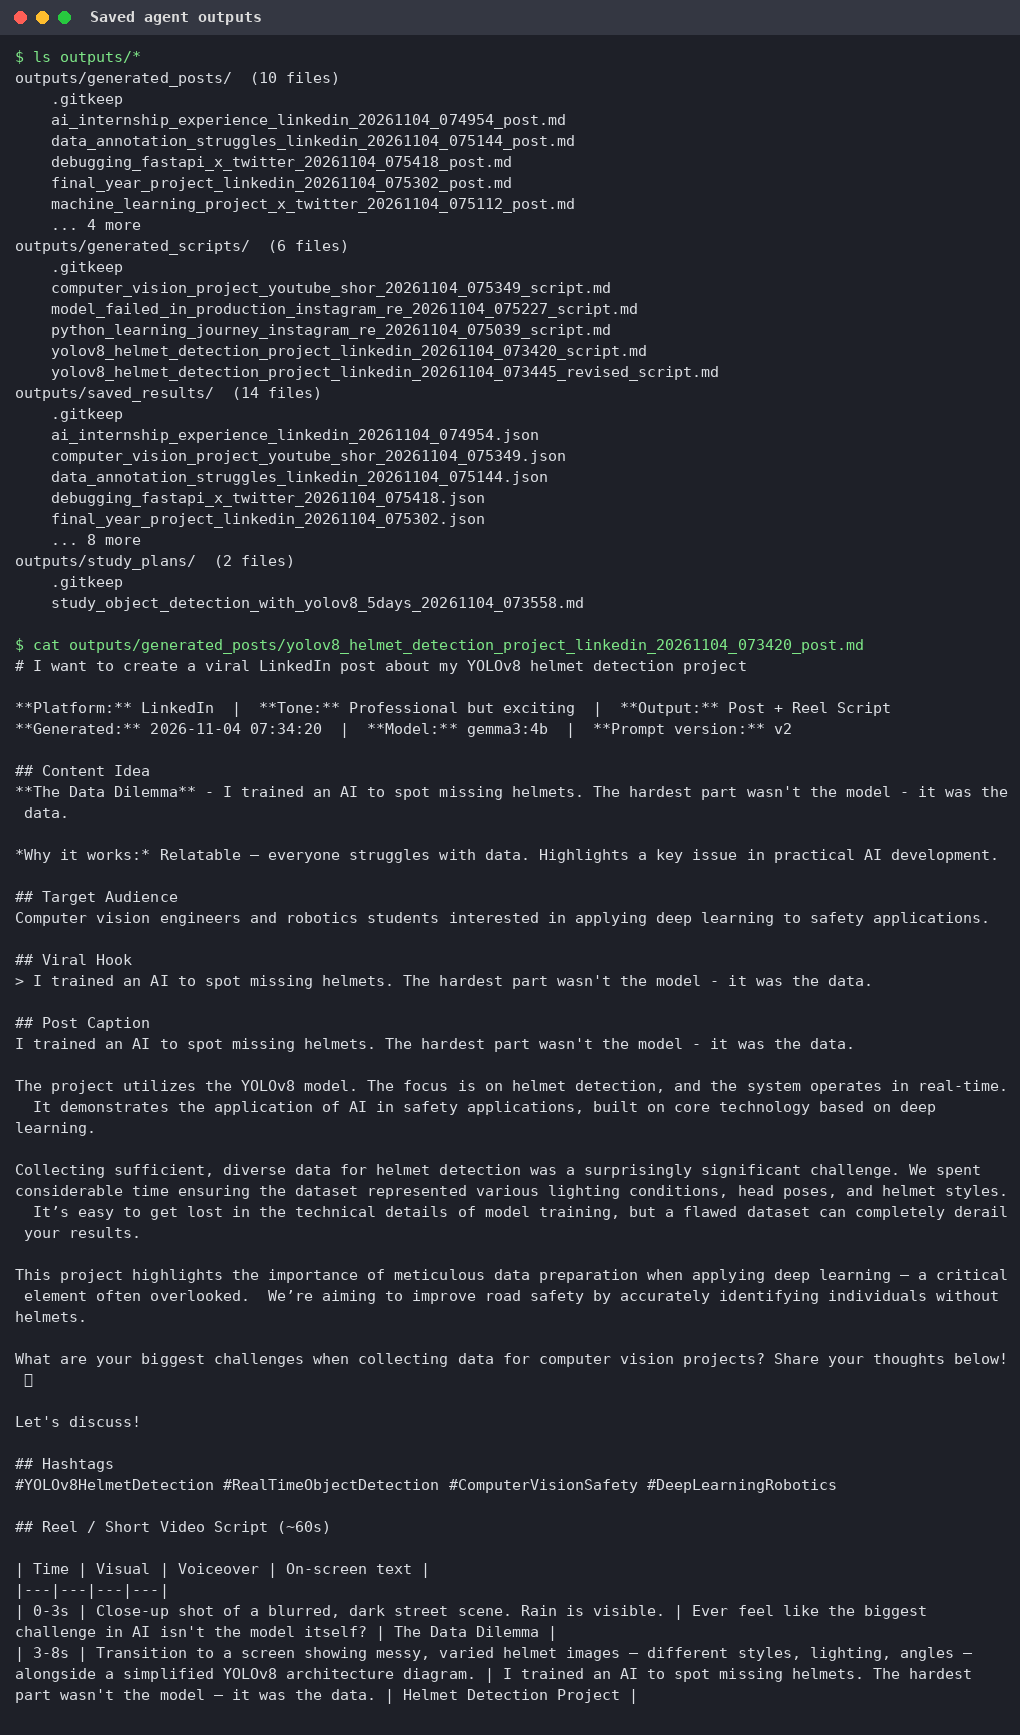

In [ ]:
listing = []
for sub in ["generated_posts", "generated_scripts", "saved_results", "study_plans"]:
    files_ = sorted((WORK / "outputs" / sub).glob("*"))
    listing.append(f"outputs/{sub}/  ({len(files_)} files)")
    listing += [f"    {f.name}" for f in files_[:6]] + ([f"    ... {len(files_)-6} more"] if len(files_) > 6 else [])
md_file = Path(res["final_output"]["saved_file"])
content = md_file.read_text().splitlines()
text = "$ ls outputs/*\n" + "\n".join(listing) + f"\n\n$ cat {md_file.relative_to(WORK)}\n" + "\n".join(content[:38])
terminal_png(text, "screenshots/saved_file_output.png", "Saved agent outputs", max_lines=80)
display(Image("screenshots/saved_file_output.png", width=900))

## Step 16 - Architecture diagram

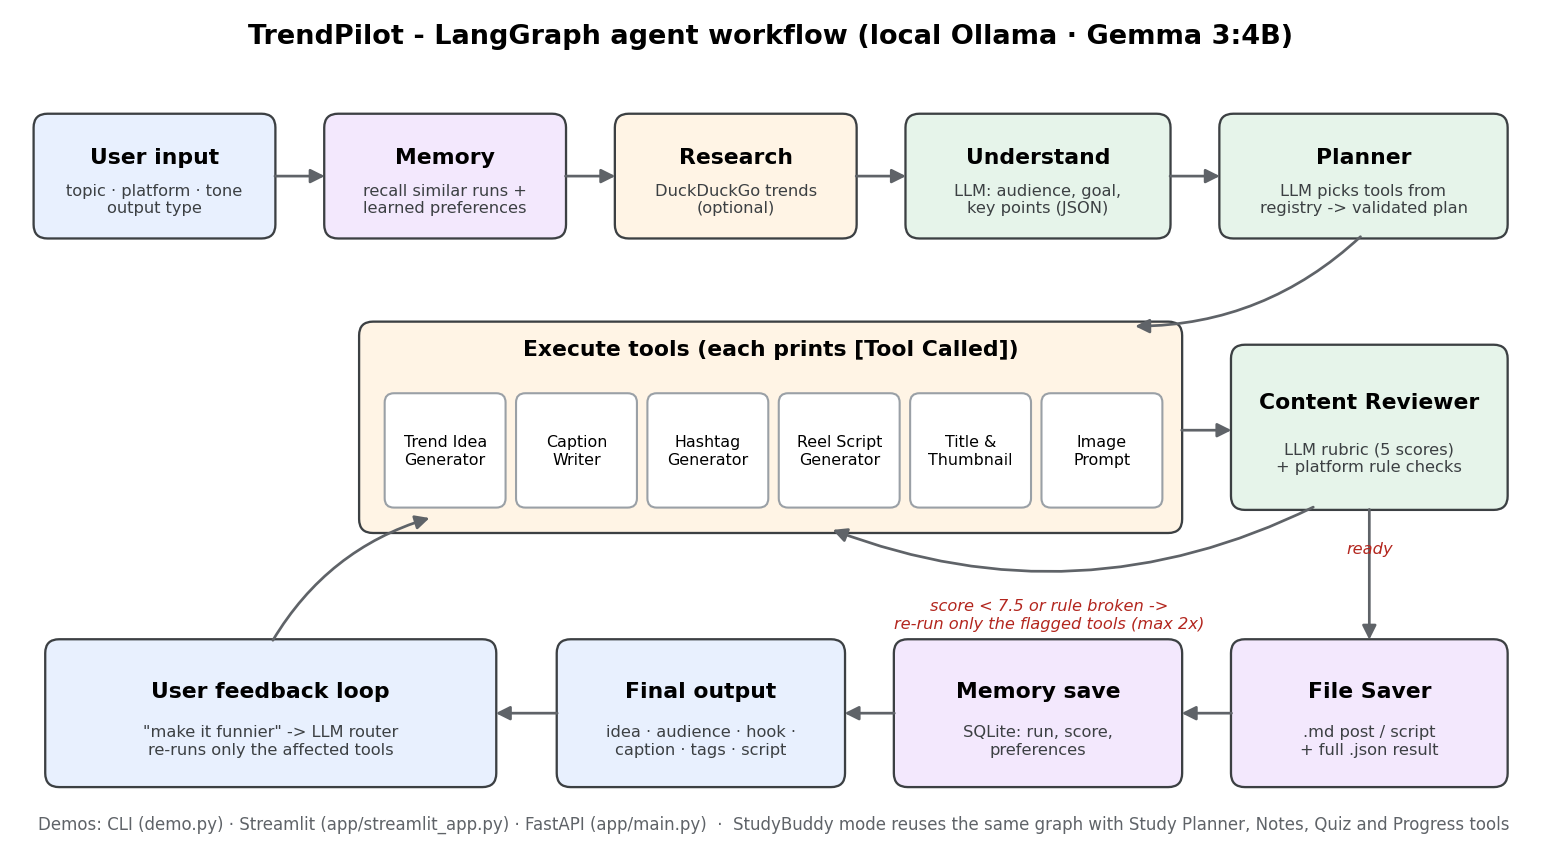

In [ ]:
from scripts.screens import architecture_png
architecture_png("screenshots/architecture.png")
display(Image("screenshots/architecture.png", width=950))

## Step 17 - FastAPI demo (Option C)
Starts the API in the background and calls it like any client would. (Docs at `/docs` when run locally.)

In [ ]:
api = subprocess.Popen([sys.executable, "-m", "uvicorn", "app.main:app", "--port", "8000"],
                       stdout=open("/content/api.log" if IN_COLAB else os.devnull, "w"), stderr=subprocess.STDOUT)
for _ in range(60):
    try:
        if requests.get("http://localhost:8000/health", timeout=2).ok: break
    except Exception: time.sleep(1)
print("GET /health ->", requests.get("http://localhost:8000/health").json())
r = requests.post("http://localhost:8000/generate-content", timeout=900,
                  json={"topic": "Debugging FastAPI at 2am", "platform": "X / Twitter", "tone": "Funny", "output_type": "Short post"})
api_out = r.json()
print("POST /generate-content ->", r.status_code)
print(json.dumps({k: api_out[k] for k in ["hook", "caption", "hashtags", "review_score", "tools_used", "saved_file"]}, indent=2))
api.terminate()

GET /health -> {'status': 'ok', 'model': 'gemma3:4b', 'version': '0.40.14', 'models': ['gemma3:4b'], 'model_ready': True}
POST /generate-content -> 200
{
  "hook": "Debugging FastAPI at 2am? Don't panic. It's a rite of passage.",
  "caption": "Debugging FastAPI feels like wrestling a Python dragon. \ud83d\udc09 FastAPI applications can break unexpectedly. Running your code with a debugger is a common technique. It's a rite of passage!",
  "hashtags": [
    "#FastAPI",
    "#PythonDebugging"
  ],
  "review_score": 8.2,
  "tools_used": [
    "Simple Memory Tool",
    "Web Trend Research (DuckDuckGo)",
    "Trend Idea Generator",
    "Caption Writer",
    "Hashtag Generator",
    "Content Reviewer",
    "File Saver Tool",
    "Simple Memory Tool (save)"
  ],
  "saved_file": "/content/agentic_ai_task_2/outputs/generated_posts/debugging_fastapi_at_2am_x_twitter_20261104_075526_post.md"
}


## Step 18 - Streamlit demo (Option B)
Starts the Streamlit app, takes a real browser screenshot of it, and (optional) gives you a **public link** to try it yourself.

Streamlit running on port 8501
Generating inside Streamlit and taking a screenshot (1-3 min)...


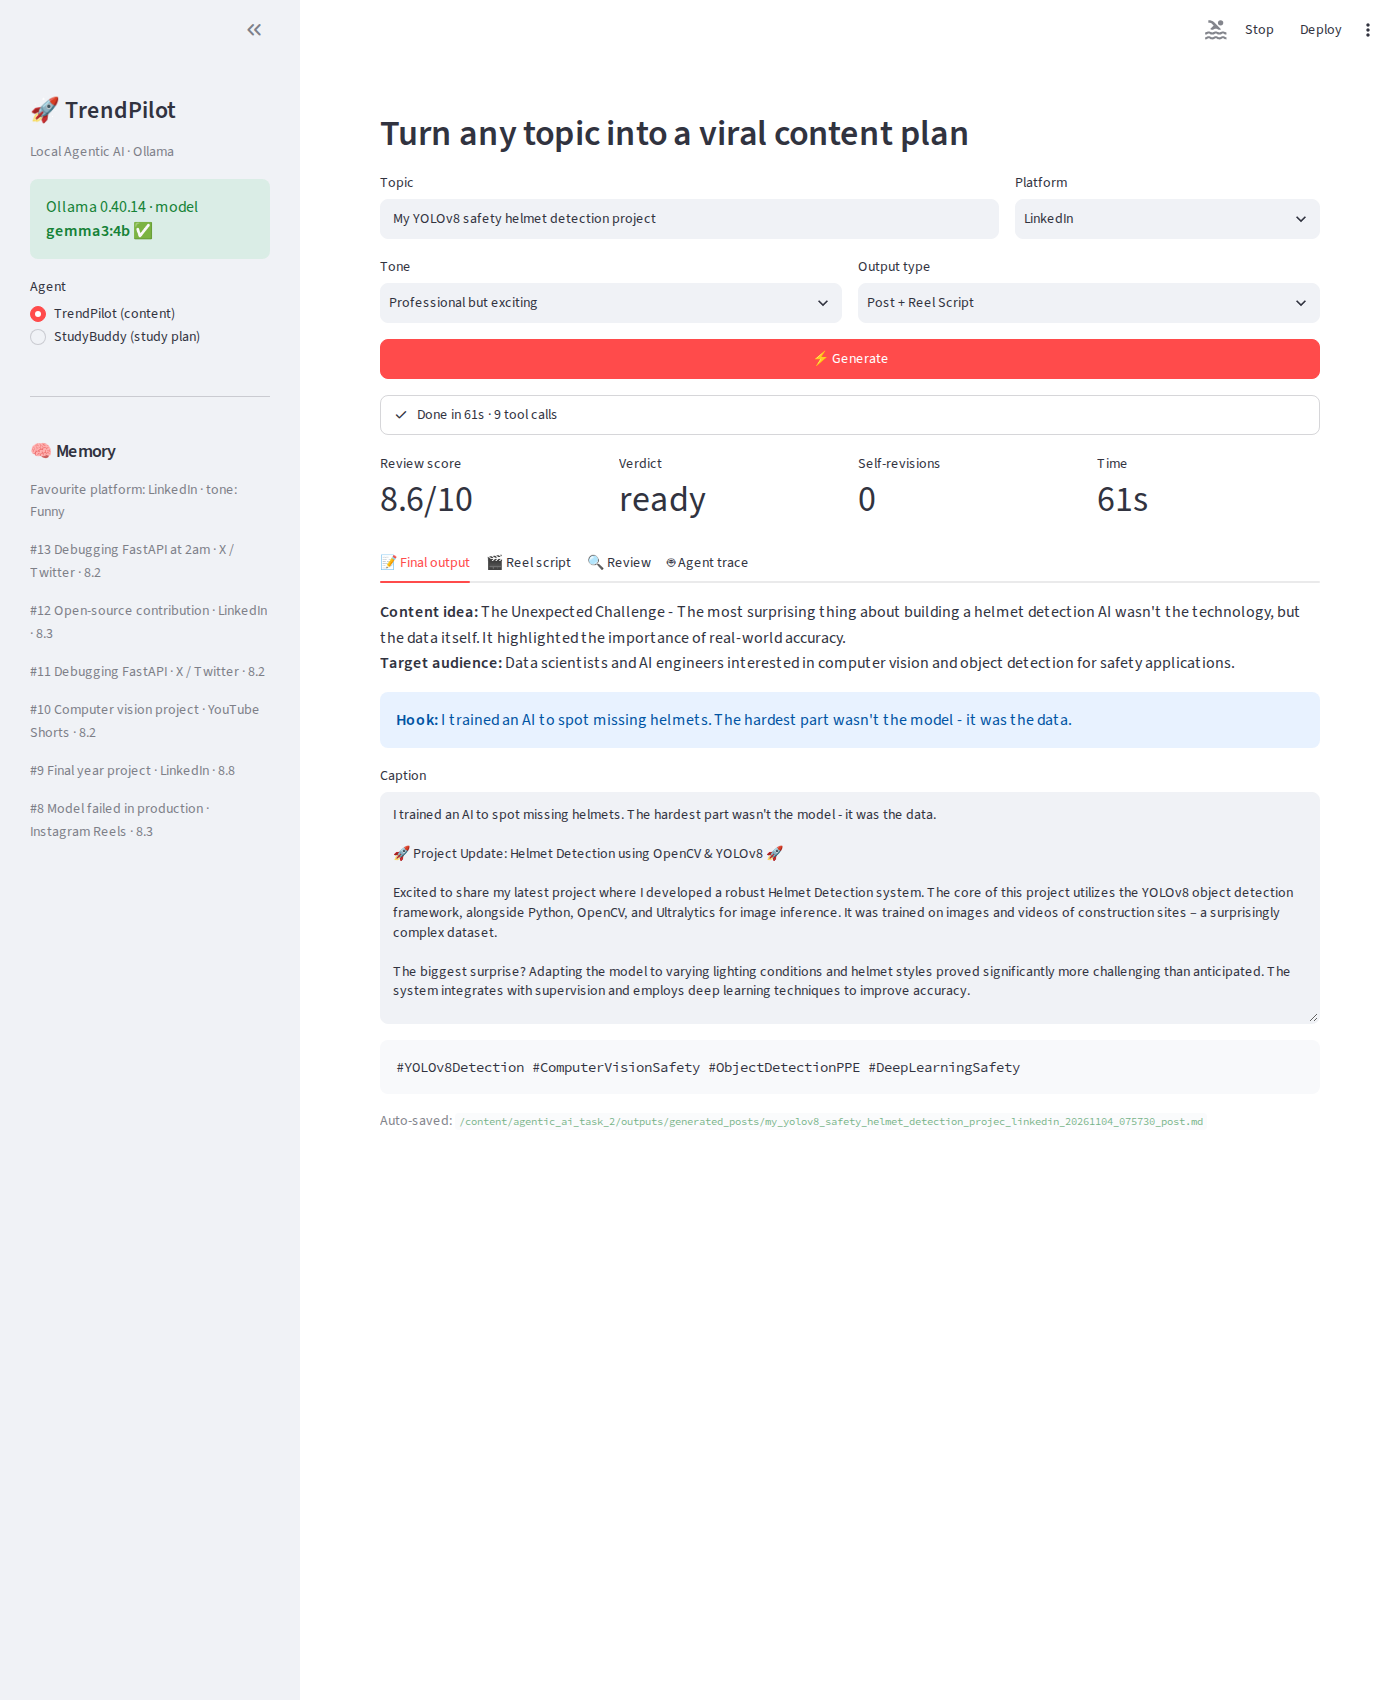

In [ ]:
MAKE_STREAMLIT_SCREENSHOT = True
SHOW_PUBLIC_LINK = True

st_proc = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app/streamlit_app.py", "--server.port", "8501",
                            "--server.headless", "true", "--browser.gatherUsageStats", "false"],
                           stdout=open("/content/streamlit.log" if IN_COLAB else os.devnull, "w"), stderr=subprocess.STDOUT)
for _ in range(60):
    try:
        if requests.get("http://localhost:8501/_stcore/health", timeout=2).ok: break
    except Exception: time.sleep(1)
print("Streamlit running on port 8501")

if MAKE_STREAMLIT_SCREENSHOT:
    try:
        import playwright  # noqa
    except ImportError:
        !pip install -q playwright && playwright install --with-deps chromium > /dev/null 2>&1
    from urllib.parse import quote
    url = "http://localhost:8501/?demo=1&topic=" + quote("My YOLOv8 safety helmet detection project")
    print("Generating inside Streamlit and taking a screenshot (1-3 min)...")
    shot = subprocess.run([sys.executable, "scripts/screens.py", "streamlit", url, "screenshots/streamlit_demo.png"],
                          capture_output=True, text=True)
    if shot.returncode == 0:
        display(Image("screenshots/streamlit_demo.png", width=950))
    else:
        print("Screenshot skipped:", (shot.stdout + shot.stderr)[-300:])

In [ ]:
if SHOW_PUBLIC_LINK and IN_COLAB:
    if not Path("/content/cloudflared").exists():
        !wget -q -O /content/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x /content/cloudflared
    tunnel = subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://localhost:8501"],
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in tunnel.stdout:
        m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
        if m:
            print("Open the Streamlit demo here:", m.group(0)); break

Open the Streamlit demo here: https://quantity-academic-cheque-msie.trycloudflare.com


## Step 19 - Final report (PDF), LinkedIn report and README results

In [ ]:
agent.memory.export_json("outputs/memory_export.json")
!python scripts/build_report.py
display(Markdown(Path("report/linkedin_portfolio_report.md").read_text()))

Report: /content/agentic_ai_task_2/report/final_report.pdf
LinkedIn report: /content/agentic_ai_task_2/report/linkedin_portfolio_report.md
{'v1_avg': 7.29, 'v2_avg': 8.21, 'v1_issues': 15, 'v2_issues': 2, 'v1_useful': 3, 'v2_useful': 9, 'n': 10, 'saved_md': 17, 'saved_json': 15, 'revised_cases': 0, 'avg_seconds': 36.5}


# TrendPilot - A Local Agentic AI Content Planner Using Ollama and Gemma 3:4B
*Hamza Nadeem - AIRI Team PITB AI Internship Task 2*

## 1. Project Overview
I built TrendPilot, a local Agentic AI assistant that runs on gemma3:4b through Ollama, so no paid API is needed. It turns any project or topic into a platform-ready content plan: a content idea, target audience, hook, caption, hashtags, a short-video script, title and thumbnail text. Instead of answering in one shot, the agent plans which tools it needs, calls them, reviews its own output against platform rules and rewrites weak parts before saving the result. The same engine also runs a StudyBuddy mode that creates study plans, notes and quizzes and tracks progress.

## 2. Tools and Technologies Used
Python, Ollama, gemma3:4b (fallbacks: Llama 3.2 3B, Qwen 2.5 3B, Phi-3 Mini), LangGraph, Streamlit, FastAPI, SQLite memory, JSON/Markdown file saving, DuckDuckGo search (optional), Google Colab (T4 GPU) and GitHub.

## 3. Agent Workflow
User gives topic -> memory recall -> agent understands the goal and audience -> planner selects tools -> tools generate content -> Content Reviewer scores it and checks platform rules -> weak parts are rewritten automatically -> File Saver stores Markdown + JSON -> final output is returned. The user can then give feedback (for example "make the hook shorter") and only the affected tools are re-run.

## 4. Tools Implemented
- **Simple Memory Tool** - Recall previous topics, platforms, styles and hooks from long-term memory (SQLite) so the new content is fresh.
- **Web Trend Research (DuckDuckGo)** - Search the web (DuckDuckGo) for fresh, real context about the topic so the content is current and factual.
- **Trend Idea Generator** - Generate 5 viral content angles for the topic and platform, score them and select the best one.
- **Caption Writer** - Write the hook, the full platform-ready post caption and a call to action in the requested tone.
- **Hashtag Generator** - Generate relevant hashtags for the platform (right count, broad + niche, no spam tags).
- **Reel Script Generator** - Create a 15-60 second short-video script: opening hook, explanation, visual suggestions and closing line.
- **Title and Thumbnail Text Generator** - Generate catchy video/post titles and short thumbnail text.
- **Post Image Prompt Generator** - Write a prompt for an AI image generator to create the post's cover image (optional extra).
- **Content Reviewer** - Review the content (hook strength, clarity, length, tone, hashtag relevance, platform readiness) and decide what to improve.
- **File Saver Tool** - Save the final result as Markdown + JSON in outputs/ (posts, scripts, full results). Mandatory last step.
- **StudyBuddy tools** - Study Planner, Notes Generator, Quiz Generator, Study Pack Reviewer and Progress Saver.

## 5. Demo and Outputs
The project has three demos: an interactive CLI (`python demo.py`), a Streamlit app (topic, platform, tone, output type, Generate, final output, Save result, live agent trace) and a FastAPI backend (`POST /generate-content`).

Example input: *I want to create a viral LinkedIn post about my YOLOv8 helmet detection project* - LinkedIn - Professional but exciting

Example hook: "I trained an AI to spot missing helmets. The hardest part wasn't the model - it was the data."

Hashtags: #YOLOv8HelmetDetection #RealTimeObjectDetection #ComputerVisionSafety #DeepLearningRobotics

Saved file: `/content/agentic_ai_task_2/outputs/generated_posts/yolov8_helmet_detection_project_linkedin_20261104_073420_post.md`

Screenshots: `screenshots/ollama_running.png`, `screenshots/demo_output.png`, `screenshots/saved_file_output.png`.

## 6. Testing
I tested the agent on 10 inputs from the brief (YOLOv8 posts, internship stories, funny Python reels, X posts, meme-style reels, portfolio posts and YouTube Shorts). The improved agent reached an average review score of 8.21/10 (baseline 7.29) and 9/10 outputs were directly usable (baseline 3/10). Weaker cases: Machine learning project.

## 7. Error Analysis
The first version broke platform rules 15 times: captions too long for X, too many and irrelevant hashtags, reel scripts longer than 60 seconds and generic cliches. I added platform-specific limits, target audience, few-shot hook examples and a banned-cliche list to the prompts, plus a reviewer loop that re-runs only the weak tool. Violations dropped to 2.

## 8. What I Learned
- How to run local LLMs with Ollama and call them from Python.
- The difference between a chatbot and an AI agent.
- How to connect tools to an LLM with a planner and a tool registry.
- Prompt design for structured JSON outputs with small models.
- How to save agent results and use SQLite memory.
- How to make an agent review and improve its own work.
- How to test, compare versions and analyse failures of an agentic workflow.

## 9. Future Improvements
- Use a larger local model (e.g. Gemma 3 12B or Qwen 2.5 7B) for funnier, more natural humour and meme-style content.
- Add a human-in-the-loop step in the UI: show 3 hooks and let the user pick before the caption is written.
- Store platform analytics (likes/comments) back into memory so the agent learns which hooks perform best.
- Add a fact-checking tool that compares claims in the caption with the user's README / project files (RAG).
- Add image generation for the cover image prompt (e.g. Stable Diffusion locally) and export the post as PDF/carousel.
- Schedule posts and track a content calendar in SQLite; deploy the FastAPI backend with Docker.

## 10. LinkedIn Post

Today, I completed AIRI Team PITB - AI Internship Task 2, where I built an end-to-end Agentic AI assistant using a local LLM through Ollama.

For this task, I developed TrendPilot, an AI agent that takes a topic and generates content ideas, LinkedIn posts, hashtags, reel scripts and saved Markdown files - running fully locally on gemma3:4b. The agent plans which tools to use, reviews its own output against platform rules and rewrites weak parts automatically. On 10 test cases, the improved version raised the average review score from 7.29 to 8.21/10. It also has a StudyBuddy mode for study plans, notes and quizzes.

This project helped me understand how agentic AI systems work beyond simple chatbot responses. I learned how to design an agent workflow, connect tools, add memory, save outputs, test different prompts, and analyze weak responses.

Tools used: Python, Ollama, gemma3:4b, LangGraph, Streamlit, FastAPI, SQLite, JSON/Markdown, and GitHub.

Key learning: Agentic AI is not only about generating text. It is about planning, using tools, storing useful information, improving outputs, and completing tasks in a structured way.

#AgenticAI #Ollama #LocalLLM #Gemma #Python #ArtificialIntelligence #AIRI #PITB #AIInternship #MachineLearning #GenerativeAI

## Step 20 - Deliverables checklist (brief section 20)

In [ ]:
saved = list((WORK/"outputs/generated_posts").glob("*.md")) + list((WORK/"outputs/generated_scripts").glob("*.md"))
checks = {
    "Complete source code (app/)": all((WORK/"app"/f).exists() for f in ["main.py", "agent.py", "tools.py", "memory.py", "prompts.py"]),
    "requirements.txt": (WORK/"requirements.txt").exists(),
    "README file": (WORK/"README.md").exists(),
    "Working demo (CLI + Streamlit + FastAPI)": (WORK/"demo.py").exists() and (WORK/"app/streamlit_app.py").exists(),
    "Screenshot: Ollama running": (WORK/"screenshots/ollama_running.png").exists(),
    "Screenshot: agent output (demo)": (WORK/"screenshots/demo_output.png").exists(),
    "Screenshot: saved file output": (WORK/"screenshots/saved_file_output.png").exists(),
    f"At least 5 saved outputs (found {len(saved)})": len(saved) >= 5,
    "Test results for 10 inputs": (WORK/"tests/test_cases.md").exists() and len(v2) == 10,
    "Error-analysis table (>=5 rows)": len(errors) >= 5,
    "Final report PDF": (WORK/"report/final_report.pdf").exists(),
    "LinkedIn-ready report section": (WORK/"report/linkedin_portfolio_report.md").exists(),
}
for k, ok in checks.items():
    print(("✅ " if ok else "❌ ") + k)

✅ Complete source code (app/)
✅ requirements.txt
✅ README file
✅ Working demo (CLI + Streamlit + FastAPI)
✅ Screenshot: Ollama running
✅ Screenshot: agent output (demo)
✅ Screenshot: saved file output
✅ At least 5 saved outputs (found 17)
✅ Test results for 10 inputs
✅ Error-analysis table (>=5 rows)
✅ Final report PDF
✅ LinkedIn-ready report section


## Step 21 - Save everything to Google Drive + make the final zip
Copies the whole project (with outputs, screenshots and report) to `My Drive/agentic_ai_task_2/` and creates
`My Drive/agentic_ai_task_2_final.zip`. For GitHub: download that zip, unzip it, and upload the **contents** of the
`agentic_ai_task_2` folder (the folder that directly contains `README.md`).

In [ ]:
for p in WORK.rglob("__pycache__"):
    shutil.rmtree(p, ignore_errors=True)
if IN_COLAB:
    shutil.copytree(WORK, DRIVE_DIR, dirs_exist_ok=True)
    print("Saved to", DRIVE_DIR)
zip_base = (DRIVE_ROOT if IN_COLAB else WORK.parent) / "agentic_ai_task_2_final"
shutil.make_archive(str(zip_base), "zip", WORK.parent, WORK.name)
print("Final zip:", f"{zip_base}.zip")

Saved to /content/drive/MyDrive/agentic_ai_task_2
Final zip: /content/drive/MyDrive/agentic_ai_task_2_final.zip
